# Lesson 4 — The sweep: how reliable are structures designed with the present Eurocode?

A code is used for many structures. The AHG model represents them by

* 9 failure modes (materials and mechanisms), each with a weight for how
  common it is,
* 3 dominating variable loads (wind, snow, imposed), also weighted,
* a grid of load proportions: 3 values of $a_G$ (share of self-weight in
  the permanent load) and 10 values of $a_Q$ (share of the variable load).

That is 9 × 3 × 3 × 10 = 810 **design situations**, each with the weight
$w = w_{mode}\,w_{load}/(n_{a_G} n_{a_Q})$. Evaluating all of them with
the present partial factors is the *status quo* of the code — the
starting point of every calibration.

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal import plots

FIG = 'figures'
os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 120)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass

## 1. The model

Everything is in `codecal/ahg2021.py` — a table of coefficients of
variation, characteristic values and weights. Read it once; it is the
whole "input" of the study.

In [2]:
model = cc.ahg_model()            # 10 M Monte-Carlo draws for the characteristic values (a few seconds)
print(model.summary())

AHG "Reliability Background of the Eurocodes", input of November 2021

reference period 50 a, target β 3.8
9 failure modes × 3 loads × 3 a_G × 10 a_Q = 810 design situations

Failure modes:
  Steel bending: Θ_R mean 1.15 CoV 0.05, R CoV 0.050 (x_k 0.830), γ_M 1.0, a_Q (0.3, 0.8), a_G (0.6, 1.0), w 0.17
  Concrete compression: Θ_R mean 0.97 CoV 0.14, R CoV 0.100 (x_k 0.844), γ_M 1.5, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.12
  Concrete bending: Θ_R mean 1.03 CoV 0.07, R CoV 0.045 (x_k 0.928), γ_M 1.15, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.4
  Glulam bending: Θ_R mean 1.00 CoV 0.10, R CoV 0.150 (x_k 0.774), γ_M 1.25, a_Q (0.2, 0.8), a_G (0.6, 1.0), w 0.035
  Timber bending: Θ_R mean 1.00 CoV 0.10, R CoV 0.200 (x_k 0.708), γ_M 1.3, a_Q (0.2, 0.8), a_G (0.6, 1.0), w 0.017
  Masonry: Θ_R mean 1.16 CoV 0.18, R CoV 0.160 (x_k 0.760), γ_M 1.5, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.12
  Aluminium bending: Θ_R mean 1.27 CoV 0.15, R CoV 0.050 (x_k 0.850), γ_M 1.1, a_Q (0.3, 0.8), a_G (0.6, 1.0), w 0.01

## 2. The status quo: β of every design situation with γ_G = 1.35, γ_Q = 1.5

`evaluate` runs FORM for each situation and returns a table — one row per
situation with its β, design parameter z and sensitivity factors.

In [3]:
t0 = time.time()
df = cc.evaluate(model, cc.START_VALUES, equation='8.12')
print(f"{len(df)} situations evaluated in {time.time() - t0:.1f} s")
print(df.head().round(3).to_string())

810 situations evaluated in 1.1 s
            mode  load  a_G    a_Q  weight      z   beta  form_iterations  alpha_Θ_R  alpha_R  alpha_Θ_E  alpha_G  alpha_P  alpha_Θ_Q  alpha_Q
0  Steel bending  wind  0.6  0.300   0.002  1.726  4.194               14     -0.241   -0.241      0.482    0.034    0.092      0.637    0.487
1  Steel bending  wind  0.6  0.356   0.002  1.744  3.987               13     -0.225   -0.225      0.449    0.028    0.075      0.662    0.503
2  Steel bending  wind  0.6  0.411   0.002  1.763  3.808               12     -0.212   -0.212      0.423    0.023    0.063      0.680    0.513
3  Steel bending  wind  0.6  0.467   0.002  1.781  3.653               12     -0.202   -0.202      0.403    0.020    0.052      0.695    0.520
4  Steel bending  wind  0.6  0.522   0.002  1.800  3.518               11     -0.193   -0.193      0.385    0.016    0.044      0.707    0.524


The headline number of the status quo is the **weighted-mean reliability
index**. The AHG reports it as 3.74; with the weights normalised to sum
to 1 it is 3.74 as well (the input weights sum to 0.999):

In [4]:
beta_mean = cc.weighted_mean_beta(df)
print(f"weighted-mean β = {beta_mean:.3f}   (target 3.8)")
print(f"range over the situations: {df['beta'].min():.2f} … {df['beta'].max():.2f}")

weighted-mean β = 3.741   (target 3.8)
range over the situations: 2.45 … 4.52


## 3. Where is the reliability high, where is it low?

Mean β per failure mode and load — the table the AHG discussed:

In [5]:
table = cc.beta_table(df)
print(table.round(2))

load                  wind  snow  imposed
mode                                     
Steel bending         3.52  3.17     3.94
Concrete compression  3.84  3.62     4.15
Concrete bending      3.42  3.15     3.78
Glulam bending        3.34  3.08     3.71
Timber bending        3.41  3.17     3.74
Masonry               4.10  3.92     4.37
Aluminium bending     3.61  3.31     4.00
Pile foundation       3.55  3.42     3.79
Shallow foundation    3.73  3.59     3.98


Snow-dominated structures are consistently below the target, imposed
load above it; masonry and concrete compression are high (large
resistance model uncertainty with bias, large γ_M), glulam and timber
low. The spread within a group is the load ratio: the next figure shows
the whole distribution, the one after it β against $a_Q$.

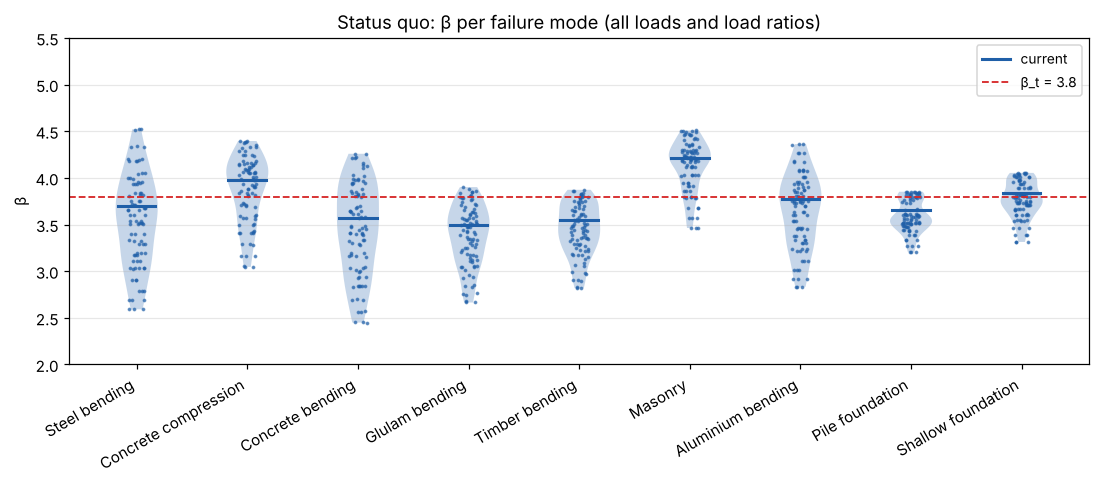

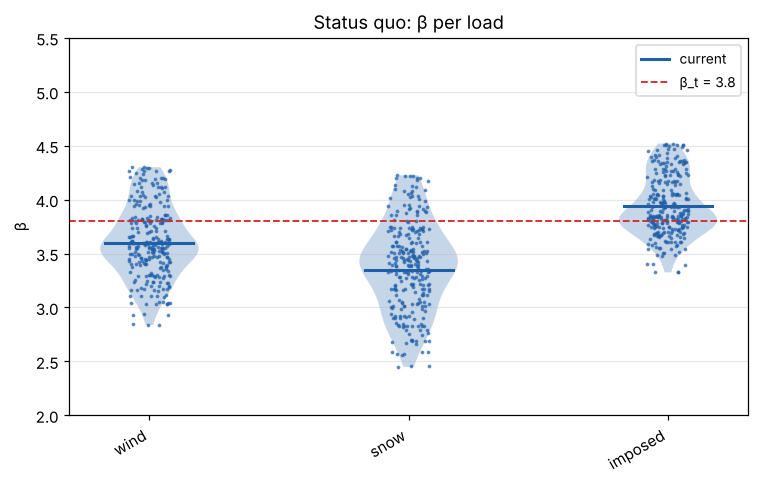

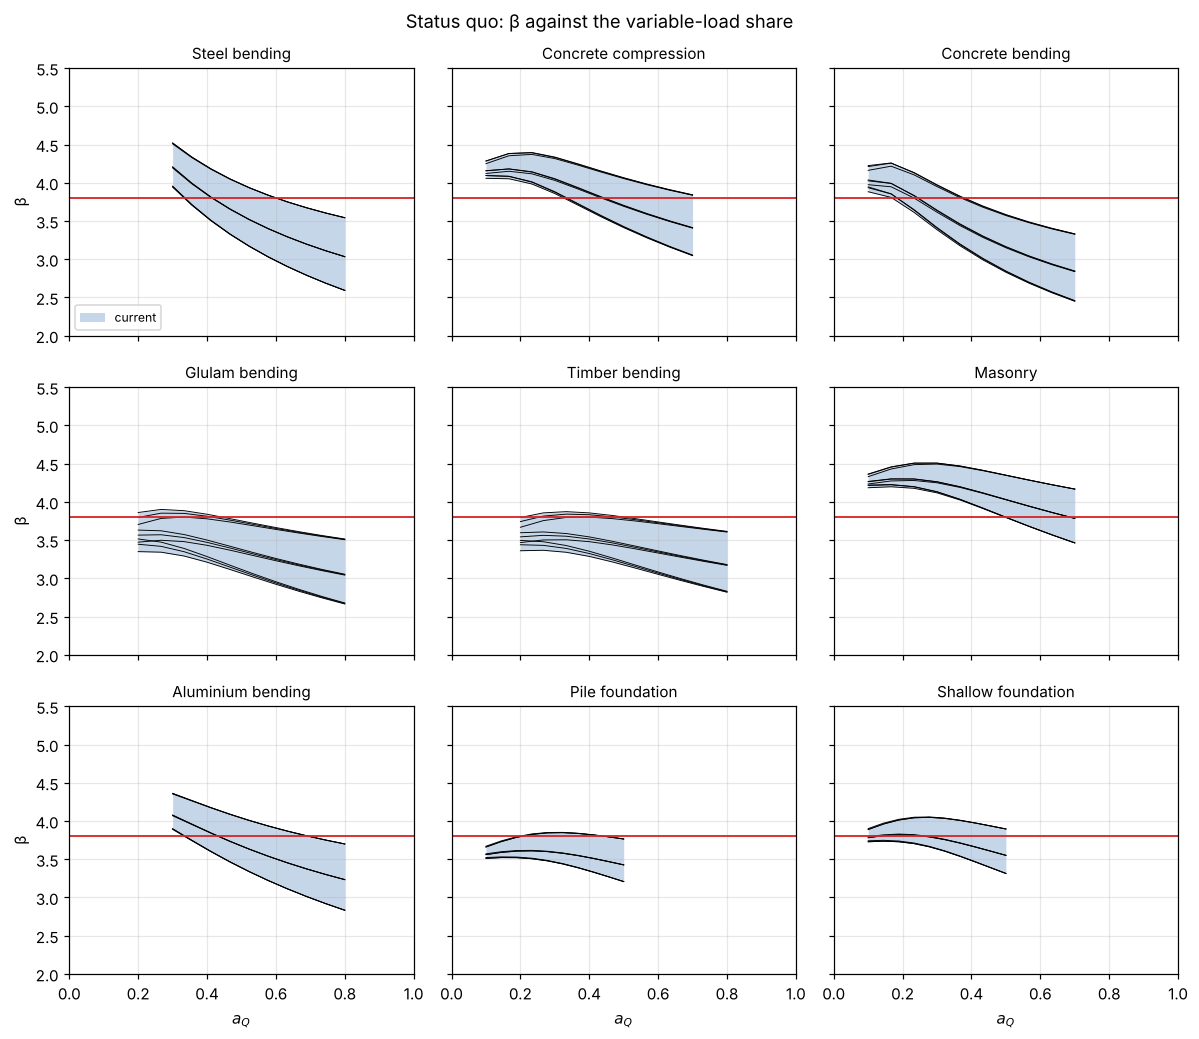

In [6]:
save(plots.plot_beta_distribution(df, by='mode', beta_target=3.8,
                                  title='Status quo: β per failure mode (all loads and load ratios)'),
     'lesson04_beta_by_mode.png')
save(plots.plot_beta_distribution(df, by='load', beta_target=3.8, title='Status quo: β per load'),
     'lesson04_beta_by_load.png')
save(plots.plot_beta_vs_aQ(df, beta_target=3.8, title='Status quo: β against the variable-load share'),
     'lesson04_beta_vs_aQ.png')

Every panel shows the same pattern: β falls with $a_Q$. With the present
factors the code is more conservative for permanent-load-dominated
structures than for variable-load-dominated ones. This is the
"reliability differentiation" that a calibration of $\gamma_G$ versus
$\gamma_Q$ tries to flatten.

## 4. Which uncertainties drive the result?

The mean sensitivity factors $\alpha_i^2$ per failure mode say which
variables the reliability depends on — and therefore which parts of the
probabilistic model deserve the most scrutiny:

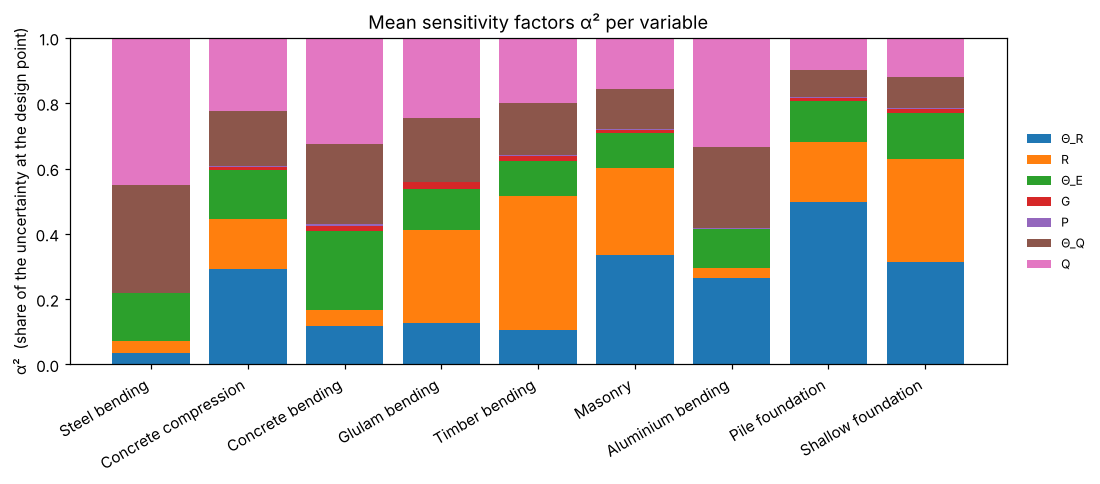

mean α² over all situations:
alpha_Θ_R    0.233
alpha_R      0.192
alpha_Θ_E    0.140
alpha_G      0.011
alpha_P      0.003
alpha_Θ_Q    0.183
alpha_Q      0.239


In [7]:
save(plots.plot_sensitivities(df, by='mode'), 'lesson04_sensitivities.png')
mean_alpha2 = (df.filter(like='alpha_') ** 2).mean().round(3)
print("mean α² over all situations:")
print(mean_alpha2.to_string())

The three model uncertainties — of the resistance ($\Theta_R$), of the
load effect ($\Theta_E$) and of the variable load ($\Theta_Q$) — together
carry more than half of the sensitivity; the self-weight and the
permanent load almost nothing (their CoVs are small and their
characteristic values are the means). The CoVs of the model
uncertainties are also the least well-known numbers of the model.
Lesson 3's exercise 3 (wind CoV 0.15 instead of 0.26) is worth doing now
on the whole model.

## 5. Weights

The weighted mean is dominated by concrete bending (w = 0.40) and the
imposed load (w = 0.5). Try a different weighting and see how much the
headline number moves — it is a modelling decision, not a measurement:

In [8]:
alt = df.copy()
alt['weight'] = 1.0 / len(alt)                                   # every situation equal
print(f"weighted-mean β, AHG weights : {beta_mean:.3f}")
print(f"weighted-mean β, equal weights: {cc.weighted_mean_beta(alt):.3f}")
df.to_csv('status_quo_sweep.csv', index=False)
print("sweep saved to status_quo_sweep.csv")

weighted-mean β, AHG weights : 3.741
weighted-mean β, equal weights: 3.646
sweep saved to status_quo_sweep.csv


## Exercises

1. Evaluate the status quo for eq. 8.13 and 8.14 (with ξ = 0.85). Which
   one gives the lowest weighted-mean β, and why (see lesson 3, section 5)?
2. Set `n_aQ=20` and check that the weighted mean hardly changes — the grid
   is fine enough.
3. Give the snow load the weight 0.4 and the wind load 0.1. How does the
   weighted mean react, and which calibration result would you expect?